In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [6]:
from sklearn.feature_extraction.text import CountVectorizer

# Load the tab-separated SMS dataset.
data = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="latin-1",
)

X_train, X_test, y_train, y_test = train_test_split(
    data["message"],
    data["label"],
    test_size=0.2,
    random_state=42,
    stratify=data["label"],
)

vectorizer = CountVectorizer()
X_train_vectorized = vectorizer.fit_transform(X_train)
X_test_vectorized = vectorizer.transform(X_test)

model = MultinomialNB()
model.fit(X_train_vectorized, y_train)
y_pred = model.predict(X_test_vectorized)

print(f"Dataset size: {len(data)} messages")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

sample_message = "Congratulations! You have won a free prize. Reply now!"
sample_vectorized = vectorizer.transform([sample_message])
print(f"Sample prediction: {model.predict(sample_vectorized)[0]}")

Dataset size: 5572 messages
Accuracy: 0.9874

Classification report:
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       966
        spam       0.99      0.92      0.95       149

    accuracy                           0.99      1115
   macro avg       0.99      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115

Sample prediction: spam


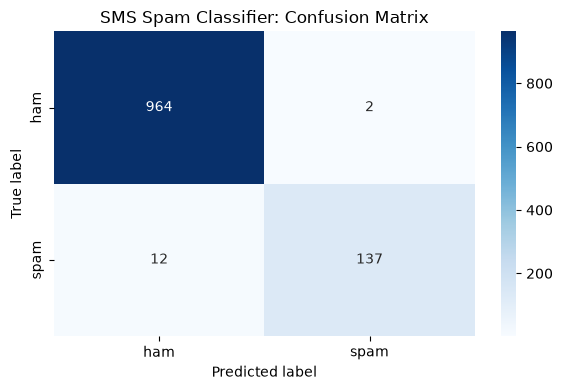

In [7]:
labels = ["ham", "spam"]
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
)
plt.title("SMS Spam Classifier: Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

In [8]:
import pickle
from pathlib import Path

pkl_path = Path("spam_classifier.pkl")
with pkl_path.open("wb") as file:
    pickle.dump({"model": model, "vectorizer": vectorizer}, file)

print(f"Saved classifier and vectorizer to: {pkl_path.resolve()}")

Saved classifier and vectorizer to: C:\Users\bk\Desktop\New folder\spam_classifier.pkl
